In [33]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import pyam
import requests
from io import StringIO
import warnings
warnings.filterwarnings('ignore')
from scipy.stats import linregress
import seaborn as sns

In [2]:
# Import CO2 data for the older period
co2_df_old_lc = pd.read_excel(
    "./input/National_LandUseChange_Carbon_Emissions_2023v1.0 (1).xlsx", 
    sheet_name="OSCAR", header=7, skiprows=[8]
)
co2_df_old_lc = co2_df_old_lc.rename(columns={"unit: Tg C/year": "year", "Global":"co2"})
co2_df_old_lc = co2_df_old_lc[["year", "co2"]]
co2_df_old_lc = co2_df_old_lc.loc[(co2_df_old_lc.year<1959)]
# Convert the units of CO2 from MtC to GtCO2
co2_df_old_lc.co2 *= 3.664/1000
co2_df_old_lc

,year,co2
0,1850,2.159179
1,1851,2.233450
2,1852,2.273055
3,1853,2.318950
4,1854,2.357534
...,...,...
104,1954,6.438938
105,1955,6.628539
106,1956,6.770047
107,1957,6.841862


In [3]:
co2_df_old = pd.read_csv("./input/GCB2023_NFCE_plotdata.csv")
co2_df_old = co2_df_old.loc[(co2_df_old.Country=="World")&(co2_df_old.Year<1959)]
co2_df_old = co2_df_old.rename(columns={"Year": "year", "Fuels_Total":"co2"})
co2_df_old = co2_df_old[["year", "co2"]]
# Convert the units of CO2 from MtC to GtCO2
co2_df_old.co2 *= 3.664/1000
assert len(co2_df_old) == len(co2_df_old_lc)
co2_df_old.co2 = co2_df_old_lc.co2.values + co2_df_old_lc.co2.values
co2_df_old

,year,co2
0,1850,4.318359
1,1851,4.466901
2,1852,4.546109
3,1853,4.637901
4,1854,4.715067
...,...,...
104,1954,12.877877
105,1955,13.257078
106,1956,13.540094
107,1957,13.683725


<Axes: xlabel='year', ylabel='co2'>

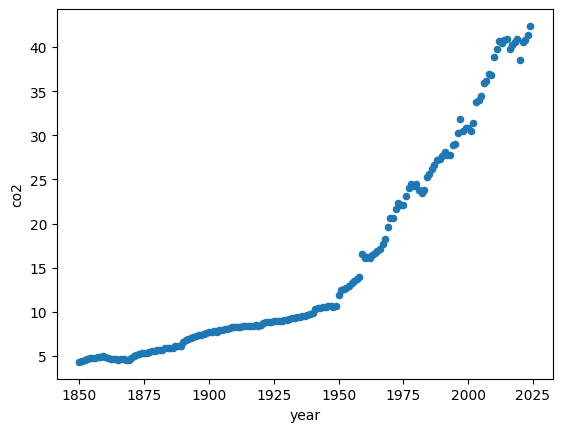

In [4]:
# Add more recent data
co2_df = pd.read_excel("./input/Global_Carbon_Budget_2024_v1.0_plus_paper.xlsx", sheet_name="Global Carbon Budget", header=21)
# Sum the emissions fro land and fossil, convert to GtCO2
co2_df["co2"] = (co2_df["fossil emissions excluding carbonation"] + co2_df["land-use change emissions"]) * 3.664
co2_df = co2_df.dropna(subset=["Year"])
co2_df["year"] = co2_df["Year"].astype(int)
co2_df = co2_df[["year", "co2"]]
co2_df = pd.concat([co2_df_old, co2_df])
co2_df.plot.scatter(x="year", y="co2")

In [5]:
# Define function to get the latest temp data
def load_temperature_data(cache_path="./input/temperature_data.csv", refresh=False):
    """
    Load NASA GISTEMP temperature anomaly data.
    Caches the CSV locally to avoid re-downloading on subsequent runs.
    
    Parameters:
        cache_path (str): Path to cached file.
        refresh (bool): If True, forces re-download of data even if cache exists.
    """   
    # Use cached version if available and refresh is False
    if os.path.exists(cache_path) and not refresh:
        print(f"Loading cached data from {cache_path}...")
        df = pd.read_csv(cache_path)
    else:
        url = "https://data.giss.nasa.gov/gistemp/tabledata_v4/GLB.Ts+dSST.csv"
        print("Downloading data from NASA GISTEMP...")
        df = pd.read_csv(url, skiprows=1)
        df.columns = df.columns.str.strip()
        df = df[['Year', 'J-D']]
        df = df.rename(columns={'Year': 'year', 'J-D': 'temp_anomaly'})
        df = df.replace('***', np.nan).dropna()
        df['temp_anomaly'] = df['temp_anomaly'].astype(float)
        
        # Save to cache for future runs
        df.to_csv(cache_path, index=False)
        print(f"Data cached at {cache_path}")

    return df

# And a function to compute TCRE given the columns of data required
def compute_ratios(temp_df, co2_df, periods):
    merged = pd.merge(temp_df, co2_df, on='year')
    results = []

    for start, end in periods:
        period_df = merged[(merged['year'] >= start) & (merged['year'] <= end)]

        if period_df.empty:
            continue

        warming = period_df['temp_anomaly'].iloc[-1] - period_df['temp_anomaly'].iloc[0]
        cumulative_emissions = period_df['co2'].sum()

        if cumulative_emissions == 0:
            ratio = np.nan
        else:
            ratio = warming / cumulative_emissions * 1000

        results.append({
            'period': f"{start}-{end}",
            'warming (°C)': warming,
            'cumulative emissions (GtCO₂)': cumulative_emissions,
            'ratio (°C/1000 GtCO₂)': ratio
        })

    return pd.DataFrame(results)

In [6]:
temp_df = load_temperature_data()

Data cached at ./input/temperature_data.csv


In [7]:
temp_df.year.min()

1880

In [8]:
bonus_temp = pd.read_csv("./input/Temperature_IPCC_Figure2_11_panel_a.csv", header=1)

In [9]:
# Make the columns consistent with temp, and the year ordering consistent too
bonus_temp = bonus_temp.rename(columns={"AR6 4-set mean": "temp_anomaly", "Year CE": "year"})[::-1]

In [10]:
bonus_offset = bonus_temp[bonus_temp.year.isin(range(1880, 1901))].mean()
bonus_offset

year            1890.000000
temp_anomaly      -0.029762
dtype: float64

In [11]:
temp_offset = temp_df[temp_df.year.isin(range(1880, 1901))].mean()
temp_offset

year            1890.000000
temp_anomaly      -0.220476
dtype: float64

In [12]:
temp_df.temp_anomaly = temp_df.temp_anomaly - (temp_offset + bonus_offset).temp_anomaly

In [13]:
assert bonus_temp[bonus_temp.year.isin(range(1850, 1901))].mean().temp_anomaly < 1e-4

In [14]:
temp_df = pd.concat([bonus_temp, temp_df[temp_df.year.isin(range(2021, 2026))]])

In [15]:
temp_df_smooth = temp_df.copy()
temp_df_smooth["temp_anomaly"] = temp_df_smooth["temp_anomaly"].rolling(window=9, center=True).mean()

<Axes: xlabel='year', ylabel='temp_anomaly'>

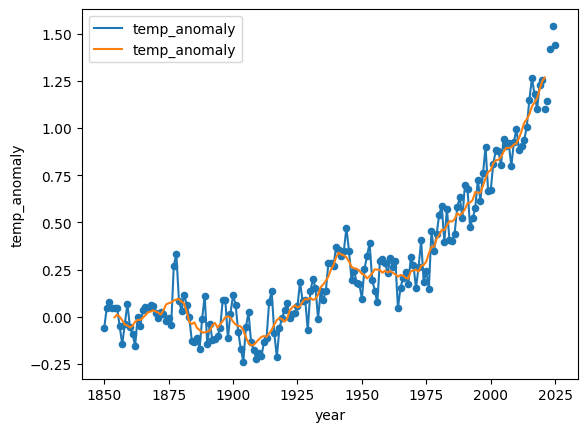

In [16]:
fig = plt.figure()
ax = fig.add_subplot()
temp_df.plot.scatter(x="year", y="temp_anomaly", ax=ax)
bonus_temp.plot(x="year", y="temp_anomaly", ax=ax)
temp_df_smooth.plot(x="year", y="temp_anomaly", ax=ax)

      period  warming (°C)  cumulative emissions (GtCO₂)  \
0  1870-1920     -0.054111                    354.599830   
1  1920-1970      0.271111                    612.914384   
2  1970-2020      1.002217                   1553.997822   

   ratio (°C/1000 GtCO₂)  
0              -0.152598  
1               0.442331  
2               0.644928  


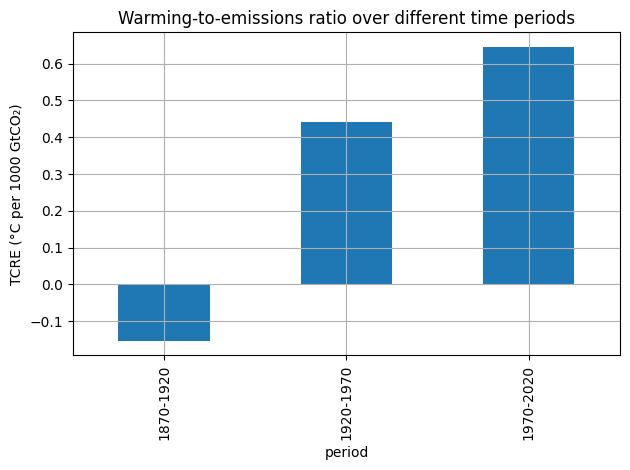

Difference between latest and 2020 latest value is:


1.4580211576532984

In [17]:
# Calculate using rolling values
periods = [(1870, 1920), (1920, 1970), (1970, 2020)]
results = compute_ratios(temp_df_smooth, co2_df, periods)
print(results)

# Optional: plot
results.plot(x='period', y='ratio (°C/1000 GtCO₂)', kind='bar', legend=False)
plt.ylabel("TCRE (°C per 1000 GtCO₂)")
plt.title("Warming-to-emissions ratio over different time periods")
plt.grid(True)
plt.tight_layout()
plt.show()
print("Difference between latest and 2020 latest value is:")
results.iloc[-1, -1] / results.iloc[-2, -1]

Computing ratios...
      period  warming (°C)  cumulative emissions (GtCO₂)  \
0  1850-1900         0.175                    283.871697   
1  1900-1950        -0.020                    463.043631   
2  1950-2000         0.573                   1106.875845   

   ratio (°C/1000 GtCO₂)  
0               0.616476  
1              -0.043192  
2               0.517673  


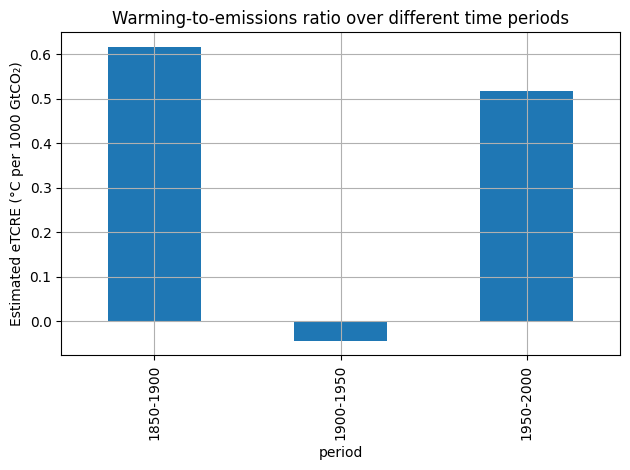

-11.985264733676562

In [18]:
# Calculate using unrounded values?
periods = [
    #(1850, 1950), (1900, 2000), (1950, 2010), (1850, 2020), (1850, 2025)]
    #(1900, 1940), (1940, 1980), (1980, 2020), (1985, 2025)
    (1850, 1900), (1900, 1950), (1950, 2000), 
]

print("Computing ratios...")
results = compute_ratios(temp_df, co2_df, periods)
print(results)

# Optional: plot
results.plot(x='period', y='ratio (°C/1000 GtCO₂)', kind='bar', legend=False)
plt.ylabel("Estimated eTCRE (°C per 1000 GtCO₂)")
plt.title("Warming-to-emissions ratio over different time periods")
plt.grid(True)
plt.tight_layout()
plt.show()
results.iloc[-1, -1] / results.iloc[-2, -1]

In [21]:
# Do this for all 50-year intervals
cumco2 = "Cumulative CO2"
def add_interval_ratio(
    df: pd.DataFrame,
    interval: int,
    col_a: str,
    col_b: str,
    result_col: str = "ratio",
) -> pd.DataFrame:
    """
    Adds a column computed as:
        (A(t) - A(t - interval)) / (B(t) - B(t - interval)) * 1000
 
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with a yearly time-series. Must have a DatetimeIndex
        (or integer year index) sorted in ascending order.
    interval : int
        Number of years to look back.
    col_a : str
        Numerator column name.
    col_b : str
        Denominator column name.
    result_col : str
        Name for the new column (default: "ratio").
 
    Returns
    -------
    pd.DataFrame
        Original DataFrame with the new ratio column appended.
    """
    df = df.copy()
 
    delta_a = df[col_a] - df[col_a].shift(interval)
    delta_b = df[col_b] - df[col_b].shift(interval)
 
    # Avoid division by zero — produces NaN where denominator is 0. Multiply by 1000 for unit conversion reasons
    df[result_col] = np.where(delta_b == 0, np.nan, delta_a / delta_b) * 1000
 
    return df

In [22]:
df = pd.merge(temp_df, co2_df, on="year")
df[cumco2] = df["co2"].cumsum()
df["temp_roll"] = df["temp_anomaly"].rolling(window=10).mean() 
df = add_interval_ratio(df, 50, "temp_anomaly", cumco2, "TCRE")
df = add_interval_ratio(df, 50, "temp_roll", cumco2, "RollingTCRE")
df

,year,temp_anomaly,co2,Cumulative CO2,temp_roll,TCRE,RollingTCRE
0,1850,-0.059000,4.318359,4.318359,NaN,NaN,NaN
1,1851,0.049000,4.466901,8.785260,NaN,NaN,NaN
2,1852,0.079000,4.546109,13.331369,NaN,NaN,NaN
3,1853,0.046000,4.637901,17.969270,NaN,NaN,NaN
4,1854,0.049000,4.715067,22.684337,NaN,NaN,NaN
...,...,...,...,...,...,...,...
170,2020,1.256000,38.565520,2585.771314,1.090400,0.640405,0.563061
171,2021,1.100238,40.544516,2626.315830,1.112324,0.609169,0.579932
172,2022,1.140238,40.834873,2667.150703,1.135748,0.559117,0.587739
173,2023,1.420238,41.416474,2708.567176,1.184171,0.638487,0.604329


In [23]:
dfmax = add_interval_ratio(df, df.year.max() - df.year.min(), "temp_anomaly", cumco2, "TCREMaxTime")
dfmax = add_interval_ratio(dfmax, df.year.max() - df.year.min()-9, "temp_roll", cumco2, "TCRERollingMaxTime")
dfmax

,year,temp_anomaly,co2,Cumulative CO2,temp_roll,TCRE,RollingTCRE,TCREMaxTime,TCRERollingMaxTime
0,1850,-0.059000,4.318359,4.318359,NaN,NaN,NaN,NaN,NaN
1,1851,0.049000,4.466901,8.785260,NaN,NaN,NaN,NaN,NaN
2,1852,0.079000,4.546109,13.331369,NaN,NaN,NaN,NaN,NaN
3,1853,0.046000,4.637901,17.969270,NaN,NaN,NaN,NaN,NaN
4,1854,0.049000,4.715067,22.684337,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
170,2020,1.256000,38.565520,2585.771314,1.090400,0.640405,0.563061,NaN,NaN
171,2021,1.100238,40.544516,2626.315830,1.112324,0.609169,0.579932,NaN,NaN
172,2022,1.140238,40.834873,2667.150703,1.135748,0.559117,0.587739,NaN,NaN
173,2023,1.420238,41.416474,2708.567176,1.184171,0.638487,0.604329,NaN,NaN


In [24]:
df_long = df.melt(
    id_vars=[c for c in df.columns if c not in ["TCRE", "RollingTCRE"]],
    value_vars=["TCRE", "RollingTCRE"],
    var_name="type",
    value_name="value",
)
df_long[df_long["type"]!="TCRE"]

,year,temp_anomaly,co2,Cumulative CO2,temp_roll,type,value
175,1850,-0.059000,4.318359,4.318359,NaN,RollingTCRE,NaN
176,1851,0.049000,4.466901,8.785260,NaN,RollingTCRE,NaN
177,1852,0.079000,4.546109,13.331369,NaN,RollingTCRE,NaN
178,1853,0.046000,4.637901,17.969270,NaN,RollingTCRE,NaN
179,1854,0.049000,4.715067,22.684337,NaN,RollingTCRE,NaN
...,...,...,...,...,...,...,...
345,2020,1.256000,38.565520,2585.771314,1.090400,RollingTCRE,0.563061
346,2021,1.100238,40.544516,2626.315830,1.112324,RollingTCRE,0.579932
347,2022,1.140238,40.834873,2667.150703,1.135748,RollingTCRE,0.587739
348,2023,1.420238,41.416474,2708.567176,1.184171,RollingTCRE,0.604329


In [25]:
dfmax["TCREMaxTime"].iat[-1]

0.5822510308558196

In [26]:
dfmax["TCRERollingMaxTime"].iat[-1]

0.45596836312070066

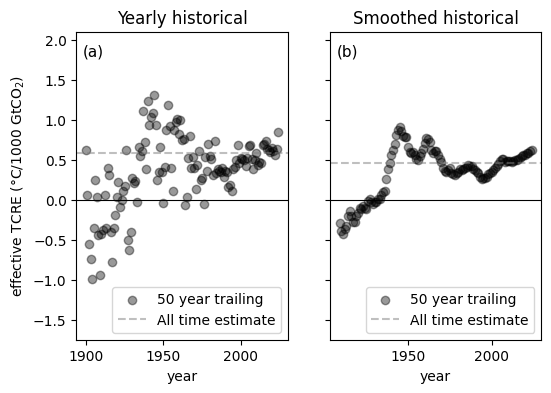

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

ax1.scatter(
    df_long[df_long["type"] == "TCRE"]["year"],
    df_long[df_long["type"] == "TCRE"]["value"],
    c="black",
    alpha=0.4
)
ax1.set_title("Yearly historical")
ax1.set_xlabel("year")
ax1.set_ylabel("effective TCRE (°C/1000 GtCO$_2$)")
ax1.axhline(dfmax["TCREMaxTime"].iat[-1], color="grey", alpha=0.5, linestyle="--")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.legend(["50 year trailing", "All time estimate"], loc="lower right")
ax2.scatter(
    df_long[df_long["type"] == "RollingTCRE"]["year"],
    df_long[df_long["type"] == "RollingTCRE"]["value"],
    c="black",
    alpha=0.4
)
ax2.axhline(dfmax["TCRERollingMaxTime"].iat[-1], color="grey", alpha=0.5, linestyle="--")
ax2.set_title("Smoothed historical")
ax2.set_xlabel("year")
ax1.set_ylim(-1.75, 2.1)
ax2.axhline(0, color="black", linewidth=0.8)
ax1.text(0.03, 0.96, "(a)", transform=ax1.transAxes,
         fontsize=11, va="top", ha="left")
ax2.text(0.03, 0.96, "(b)", transform=ax2.transAxes,
         fontsize=11, va="top", ha="left")
ax2.legend(["50 year trailing", "All time estimate"], loc="lower right")


In [28]:
#fig, ax1 = plt.subplots(figsize=(10, 4))
sns.stripplot(
    data=df_long.dropna(),
    x="type",
    y="value",
    jitter=True,
    dodge=True,
    hue="year",
    palette="crest", 
)

NameError: name 'sns' is not defined

In [29]:
# Import data
ar6 = pyam.IamDataFrame("./input/AR6_Scenarios_Database_World_v1.1.csv")
ar6harm = pyam.IamDataFrame("./input/1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv")

pyam.core - INFO: Reading file input\AR6_Scenarios_Database_World_v1.1.csv
pyam.core - INFO: Reading file input\1652361598937-ar6_emissions_vetted_infillerdatabase_10.5281-zenodo.6390768 (1).csv


In [30]:
infillstring = "AR6 climate diagnostics|Harmonized|"
co2 = "Emissions|CO2"
eni = "|Energy and Industrial Processes"
afolu = "|AFOLU"

useful = ar6harm.filter(variable=infillstring + co2 + "*").add(
    infillstring+co2+eni, infillstring+co2+afolu, co2, ignore_units=True
)

In [31]:
ar6harm.meta

Empty DataFrame
Columns: []
Index: [(AIM/CGE 2.0, SSP1-26), (AIM/CGE 2.0, SSP1-34), (AIM/CGE 2.0, SSP1-45), (AIM/CGE 2.0, SSP1-Baseline), (AIM/CGE 2.0, SSP4-26), (AIM/CGE 2.0, SSP4-34), (AIM/CGE 2.0, SSP4-45), (AIM/CGE 2.0, SSP4-Baseline), (AIM/CGE 2.1, CD-LINKS_INDC2030i_1600), (AIM/CGE 2.1, CD-LINKS_INDCi), (AIM/CGE 2.1, CD-LINKS_NDC2030i_1000), (AIM/CGE 2.1, CD-LINKS_NPi2020_1000), (AIM/CGE 2.1, CD-LINKS_NPi2020_1600), (AIM/CGE 2.1, CD-LINKS_NPi2020_400), (AIM/CGE 2.1, CO_Bridge), (AIM/CGE 2.1, CO_CurPol), (AIM/CGE 2.2, EN_INDCi2030_1000), (AIM/CGE 2.2, EN_INDCi2030_1000f), (AIM/CGE 2.2, EN_INDCi2030_1200), (AIM/CGE 2.2, EN_INDCi2030_1200f), (AIM/CGE 2.2, EN_INDCi2030_1400), (AIM/CGE 2.2, EN_INDCi2030_1400f), (AIM/CGE 2.2, EN_INDCi2030_1600), (AIM/CGE 2.2, EN_INDCi2030_1600f), (AIM/CGE 2.2, EN_INDCi2030_1800), (AIM/CGE 2.2, EN_INDCi2030_1800f), (AIM/CGE 2.2, EN_INDCi2030_500f), (AIM/CGE 2.2, EN_INDCi2030_600f), (AIM/CGE 2.2, EN_INDCi2030_700f), (AIM/CGE 2.2, EN_INDCi2030_800), (AIM/CGE 2.2, EN_INDCi2030_800f), (AIM/CGE 2.2, EN_INDCi2030_900), (AIM/CGE 2.2, EN_INDCi2030_900f), (AIM/CGE 2.2, EN_INDCi2100), (AIM/CGE 2.2, EN_NPi2020_1000), (AIM/CGE 2.2, EN_NPi2020_1000f), (AIM/CGE 2.2, EN_NPi2020_1200), (AIM/CGE 2.2, EN_NPi2020_1200f), (AIM/CGE 2.2, EN_NPi2020_1400), (AIM/CGE 2.2, EN_NPi2020_1400f), (AIM/CGE 2.2, EN_NPi2020_1600), (AIM/CGE 2.2, EN_NPi2020_1600f), (AIM/CGE 2.2, EN_NPi2020_1800), (AIM/CGE 2.2, EN_NPi2020_1800f), (AIM/CGE 2.2, EN_NPi2020_300f), (AIM/CGE 2.2, EN_NPi2020_400f), (AIM/CGE 2.2, EN_NPi2020_500f), (AIM/CGE 2.2, EN_NPi2020_600), (AIM/CGE 2.2, EN_NPi2020_600f), (AIM/CGE 2.2, EN_NPi2020_700), (AIM/CGE 2.2, EN_NPi2020_700f), (AIM/CGE 2.2, EN_NPi2020_800), (AIM/CGE 2.2, EN_NPi2020_800f), (AIM/CGE 2.2, EN_NPi2020_900), (AIM/CGE 2.2, EN_NPi2020_900f), (AIM/CGE 2.2, EN_NPi2100), (AIM/Hub-Global 2.0, 1.5C), (AIM/Hub-Global 2.0, 2.5C), (AIM/Hub-Global 2.0, 2C), (AIM/Hub-Global 2.0, Baseline), (AIM/Hub-Global 2.0, WB2C), (C-ROADS-5.005, Ratchet-1.5-allCDR), (C-ROADS-5.005, Ratchet-1.5-limCDR), (C-ROADS-5.005, Ratchet-1.5-limCDR-noOS), (C-ROADS-5.005, Ratchet-1.5-noCDR), (C-ROADS-5.005, Ratchet-1.5-noCDR-noOS), (C-ROADS-5.005, Reference), (C3IAM 2.0, 2C-hybrid), (C3IAM 2.0, 2C-normal), (C3IAM 2.0, 2C-with BECCS), (C3IAM 2.0, 2C-with CCS), (C3IAM 2.0, SSP2 BAU), (COFFEE 1.1, CO_2Deg2020), (COFFEE 1.1, CO_2Deg2030), (COFFEE 1.1, CO_BAU), (COFFEE 1.1, CO_Bridge), (COFFEE 1.1, CO_CurPol), (COFFEE 1.1, CO_GPP), (COFFEE 1.1, CO_NDCplus), (COFFEE 1.1, EN_INDCi2030_1000), (COFFEE 1.1, EN_INDCi2030_1000_NDCp), (COFFEE 1.1, EN_INDCi2030_1000f), (COFFEE 1.1, EN_INDCi2030_1200), (COFFEE 1.1, EN_INDCi2030_1200f), (COFFEE 1.1, EN_INDCi2030_1400), (COFFEE 1.1, EN_INDCi2030_1400f), (COFFEE 1.1, EN_INDCi2030_1600), (COFFEE 1.1, EN_INDCi2030_1600f), (COFFEE 1.1, EN_INDCi2030_1800), (COFFEE 1.1, EN_INDCi2030_1800f), (COFFEE 1.1, EN_INDCi2030_2000), (COFFEE 1.1, EN_INDCi2030_2000f), (COFFEE 1.1, EN_INDCi2030_2500), (COFFEE 1.1, EN_INDCi2030_2500f), (COFFEE 1.1, EN_INDCi2030_400f), (COFFEE 1.1, EN_INDCi2030_500), (COFFEE 1.1, EN_INDCi2030_500f), (COFFEE 1.1, EN_INDCi2030_600), (COFFEE 1.1, EN_INDCi2030_600_NDCp), (COFFEE 1.1, EN_INDCi2030_600f), ...]

[1295 rows x 0 columns]

In [32]:
useful.filter(scenario="ADVANCE_2020_1.5C-2100", model="AIM/CGE 2.0").variable

pyam.core - WARNING: Filtered IamDataFrame is empty!


[]

In [ ]:
useful.filter(variable=co2).plot(alpha=0.2)

In [ ]:
useful.filter(year=2015).timeseries()[2015].unique()

In [ ]:
tempfair = 'AR6 climate diagnostics|Surface Temperature (GSAT)|FaIRv1.6.2|50.0th Percentile'
tempmagicc = 'AR6 climate diagnostics|Surface Temperature (GSAT)|MAGICCv7.5.3|50.0th Percentile'
useful = pyam.concat([useful, ar6.filter(variable=[tempfair, tempmagicc])])

In [ ]:
useful = useful.interpolate(time=range(2015, 2101)).filter(year=range(2015, 2101))

In [ ]:
useful.filter(variable=tempfair).plot(alpha=0.2)

In [ ]:
assert useful.timeseries().isna().sum().sum() == 0
useful_ts = useful.timeseries().reset_index().drop(columns=["unit"])

In [ ]:
useful.variable

In [ ]:
def make_long(df):
    # This flips a dataframe to have different variable names as the columns and model/scenario/years as rows
    return df.melt(
        id_vars=["model", "scenario", "region", "variable"], 
        var_name="year", 
        value_name="value"
    ).pivot_table(
        index=["model", "scenario", "region", "year"], 
        columns="variable", 
        values="value"
    )

In [ ]:
useful_long = make_long(useful_ts)

In [ ]:
useful_long[cumco2] = useful_long.groupby(["model", "scenario", "region"])[co2].cumsum()

In [ ]:
useful_long[cumco2]

# Investigate the impact of this on carbon budgets

In [ ]:
plt.scatter(useful_long[cumco2], useful_long[tempfair], alpha=0.15)

In [ ]:
def fit_and_predict(df, x_col, y_col, x_list, colordots="blue", colorlines="orange", linelabel="Budget", pointlabel="Scenarios"):
    df = df[[x_col, y_col]].dropna().sort_values(by=x_col)  # Clean and sort data
    slope, intercept, _, _, _ = linregress(df[x_col], df[y_col])  # Linear regression

    predict = lambda x: slope * x + intercept  # Prediction function
    y_preds = {x: predict(x) for x in x_list}

    # Plot
    plt.scatter(df[x_col], df[y_col], label=pointlabel, color=colordots, alpha=0.08, s=10)
    plt.plot(df[x_col], predict(df[x_col]), label=linelabel, color=colorlines)
    #plt.scatter(x_list, [predict(x) for x in x_list], ce olor="orange", label="Predictions", marker="x", s=50.0)
    plt.xlabel(x_col), plt.ylabel(y_col), plt.legend(), plt.title("Linear Fit"), plt.grid(True)

    return y_preds

In [ ]:
temps_of_int = [1.5, 2.0]
cox_budget_magicc_unround = fit_and_predict(useful_long, tempmagicc, cumco2, temps_of_int)
cox_budget_magicc_unround

In [ ]:
fit_and_predict(useful_long[useful_long[tempmagicc]<2.2], tempmagicc, cumco2, temps_of_int)

In [ ]:
cox_budget_fair_unround = fit_and_predict(useful_long, tempfair, cumco2, temps_of_int)
cox_budget_fair_unround

In [ ]:
# We should subtract emissions from 2015-2019 inclusive to make this comparable with RCB calculations elsewhere
# From GCP: 55.25 Gg C -> 202.4 GtCO2
offset_emissions = 202400

In [ ]:
(useful_long[co2]<0)

In [ ]:
# Now compare this to calculating using the peak temperature
useful_long_max = useful_long.groupby(["model", "scenario", "region"]).max()

In [ ]:
useful_long_maxids_fair = useful_long.groupby(["model", "scenario", "region"])[tempfair].idxmax()
useful_fairmax = useful_long.loc[useful_long_maxids_fair[useful_long_maxids_fair==useful_long_maxids_fair]]
useful_fairmax

In [ ]:
fit_and_predict(useful_long_max, tempmagicc, cumco2, temps_of_int)

In [ ]:
fit_and_predict(useful_long_max[useful_long_max[tempmagicc]<2.2], tempmagicc, cumco2, temps_of_int)

In [ ]:
best_magicc_2C = fit_and_predict(useful_long_max[(useful_long_max[tempmagicc]<2.1)&(useful_long_max[tempmagicc]>1.9)], tempmagicc, cumco2, temps_of_int)
best_magicc_2C

In [ ]:
best_magicc_1p5C = fit_and_predict(useful_long_max[(useful_long_max[tempmagicc]<1.6)&(useful_long_max[tempmagicc]>1.4)], tempmagicc, cumco2, temps_of_int)
best_magicc_1p5C

In [ ]:
best_fair_1p5C = fit_and_predict(useful_long_max[(useful_long_max[tempfair]<1.6)&(useful_long_max[tempfair]>1.4)], tempfair, cumco2, temps_of_int)
best_fair_1p5C

In [ ]:
best_fair_2C = fit_and_predict(useful_long_max[(useful_long_max[tempfair]<2.1)&(useful_long_max[tempfair]>1.9)], tempfair, cumco2, temps_of_int)
best_fair_2C

In [ ]:
diff1p5magicc = -best_magicc_1p5C[1.5] + cox_budget_magicc_unround[1.5]
diff1p5magicc

In [ ]:
diff2magicc = -best_magicc_2C[2] + cox_budget_magicc_unround[2]
diff2magicc

In [ ]:
diff1p5fair = -best_fair_1p5C[1.5] + cox_budget_fair_unround[1.5]
diff1p5fair

In [ ]:
diff2fair = -best_fair_2C[2] + cox_budget_fair_unround[2]
diff2fair

In [ ]:
fit_and_predict(useful_long_max, tempfair, cumco2, temps_of_int)

In [ ]:
cox_budget_fair_unround

# Establish the reason for the close alignment

In [ ]:
def avg_year_of_peak(
    df: pd.DataFrame,
    peak_col: str,
    filter_col: str,
    filter_value: float,
    filter_window: float,
) -> pd.Series:
    """
    For each (model, scenario, region) combination, find the year at which
    `peak_col` is maximised, then return the average of those peak years —
    but only for combinations where `filter_col` has at least one value
    within [filter_value - filter_window, filter_value + filter_window].

    Parameters
    ----------
    df : pd.DataFrame
        MultiIndex DataFrame with levels (model, scenario, region, year).
    peak_col : str
        Column whose maximum value determines the peak year.
    filter_col : str
        Column used to decide whether a (model, scenario, region) is included.
    filter_value : float
        Central value for the filter window.
    filter_window : float
        Half-width of the filter window (inclusive).

    Returns
    -------
    float
        Average peak year across all qualifying (model, scenario, region) groups.
    """
    cols = list(dict.fromkeys([filter_col, peak_col]))  # preserves order
    subset = df[cols]

    # --- Step 1: filter to groups where filter_col is within the window -------
    lo, hi = filter_value - filter_window, filter_value + filter_window
    in_window = df[filter_col].between(lo, hi)               # bool mask over all rows
    qualifying_groups = (
        in_window
        .groupby(level=["model", "scenario", "region"])
        .any()                                                # True if ANY row qualifies
    )
    qualifying_index = qualifying_groups[qualifying_groups].index  # MultiIndex of keepers

    df_filtered = df[
        df.index.droplevel("year").isin(qualifying_index)
    ]

    # --- Step 2: find the year of the peak value per group --------------------
    peak_years = (
        df_filtered[peak_col]
        .groupby(level=["model", "scenario", "region"])
        .idxmax()
        .apply(lambda idx: idx[-1] if isinstance(idx, tuple) else idx)
    )

    # --- Step 3: return the average peak year ---------------------------------
    return peak_years.mean()

In [ ]:
avg_year_of_peak(useful_long, tempfair, tempfair, 1.5, 0.1)

In [ ]:
avg_year_of_peak(useful_long, co2, tempfair, 1.5, 0.1)

# Compare the two estimates



In [ ]:
fit_and_predict(
    useful_long[(useful_long[tempfair]<2.05)], 
    tempfair, cumco2, temps_of_int, linelabel="Exceedance budget", pointlabel="All temperatures"
)
fit_and_predict(
    useful_long_max[(useful_long_max[tempfair]<2.1)&(useful_long_max[tempfair]>1.9)],
    tempfair, cumco2, temps_of_int, "cyan", "yellow", "Avoidance budget around 2C", "Peak temperature"
)
fit_and_predict(
    useful_long_max[(useful_long_max[tempfair]<1.6)&(useful_long_max[tempfair]>1.45)],
    tempfair, cumco2, temps_of_int, "cyan", "yellow", "Avoidance budget around 1.5C", "Peak temperature")
fit_and_predict(
    useful_fairmax[(useful_fairmax[tempfair]<2.05)],
    tempfair, cumco2, temps_of_int, "green", "pink", "Avoidance budget across all temps", "Peak temperature"
)